# 00 — Розвідувальний аналіз даних (EDA)

**Пререквізит ЛР1.** Мета — ухвалити проєктні рішення: типи колонок, захищена ознака, проксі, потреба в інжектуванні пропусків.

> Статистики в цьому ноутбуці рахуються на **повному** наборі — це допустимо лише для *розуміння* даних.
> Жодне число звідси не переноситься в конфігурацію чи конвеєр: частки пропусків, медіани тощо
> препроцесор обчислює сам, у `fit`, лише на тренувальній підвибірці.


In [1]:
import sys
from pathlib import Path
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

pd.set_option("display.width", 200)
pd.set_option("display.max_columns", 50)
REPORTS = ROOT / "reports"
REPORTS.mkdir(exist_ok=True)

# Стиль графіків: один акцентний колір, приглушені осі й сітка
ACCENT, INK, MUTED, SURFACE = "#2a78d6", "#0b0b0b", "#52514e", "#fcfcfb"
plt.rcParams.update({
    "figure.facecolor": SURFACE, "axes.facecolor": SURFACE, "savefig.facecolor": SURFACE,
    "axes.edgecolor": "#d0cfca", "axes.labelcolor": MUTED, "xtick.color": MUTED, "ytick.color": MUTED,
    "axes.titlecolor": INK, "axes.titlesize": 10, "axes.labelsize": 9, "xtick.labelsize": 8, "ytick.labelsize": 8,
    "axes.grid": True, "grid.color": "#ecebe7", "grid.linewidth": 0.8, "axes.axisbelow": True,
    "axes.spines.top": False, "axes.spines.right": False, "figure.dpi": 110,
})

In [2]:
from src.data import load_data_config, load_raw
dc = load_data_config()
df = load_raw(dc)            # сирі дані, без інжектованих пропусків
print(df.shape)
df.head()

(5630, 20)


,CustomerID,Churn,Tenure,PreferredLoginDevice,CityTier,WarehouseToHome,PreferredPaymentMode,Gender,HourSpendOnApp,NumberOfDeviceRegistered,PreferedOrderCat,SatisfactionScore,MaritalStatus,NumberOfAddress,Complain,OrderAmountHikeFromlastYear,CouponUsed,OrderCount,DaySinceLastOrder,CashbackAmount
0,50001,1,4.0,Mobile Phone,3,6.0,Debit Card,Female,3.0,3,Laptop & Accessory,2,Single,9,1,11.0,1.0,1.0,5.0,159.93
1,50002,1,NaN,Phone,1,8.0,UPI,Male,3.0,4,Mobile,3,Single,7,1,15.0,0.0,1.0,0.0,120.90
2,50003,1,NaN,Phone,1,30.0,Debit Card,Male,2.0,4,Mobile,3,Single,6,1,14.0,0.0,1.0,3.0,120.28
3,50004,1,0.0,Phone,3,15.0,Debit Card,Male,2.0,4,Laptop & Accessory,5,Single,8,0,23.0,0.0,1.0,3.0,134.07
4,50005,1,0.0,Phone,1,12.0,CC,Male,NaN,3,Mobile,5,Single,3,0,11.0,1.0,1.0,3.0,129.60


## 1. Типи колонок і словник даних

In [3]:
dictionary = pd.read_excel(ROOT / dc["source"]["path"], sheet_name="Data Dict", header=1).iloc[:, 1:]
dictionary.columns = ["sheet", "variable", "description"]
types = pd.DataFrame({"dtype": df.dtypes.astype(str), "n_unique": df.nunique()})
types.join(dictionary.set_index("variable")["description"])

,dtype,n_unique,description
CustomerID,int64,5630,Unique customer ID
Churn,int64,2,Churn Flag
Tenure,float64,36,Tenure of customer in organization
PreferredLoginDevice,str,3,Preferred login device of customer
CityTier,int64,3,City tier
WarehouseToHome,float64,34,Distance in between warehouse to home of customer
PreferredPaymentMode,str,7,Preferred payment method of customer
Gender,str,2,Gender of customer
HourSpendOnApp,float64,6,Number of hours spend on mobile application or...
NumberOfDeviceRegistered,int64,6,Total number of deceives is registered on part...


## 2. Ціль: баланс класів

In [4]:
churn = df[dc["target"]].value_counts().rename_axis("Churn").to_frame("count")
churn["share"] = (churn["count"] / len(df)).round(3)
churn

,count,share
Churn,,
0,4682,0.832
1,948,0.168


## 3. Природні пропуски

In [5]:
missing = df.isna().mean().rename("missing_share").to_frame()
missing = missing[missing.missing_share > 0].sort_values("missing_share", ascending=False)
missing["policy_branch"] = np.where(missing.missing_share <= 0.10, "≤10%", ">10%")
missing.round(4)

,missing_share,policy_branch
DaySinceLastOrder,0.0545,≤10%
OrderAmountHikeFromlastYear,0.0471,≤10%
Tenure,0.0469,≤10%
OrderCount,0.0458,≤10%
CouponUsed,0.0455,≤10%
HourSpendOnApp,0.0453,≤10%
WarehouseToHome,0.0446,≤10%


Усі природні пропуски — у 7 числових колонках, 4.5–5.5%. Усі вони потрапляють у **першу** гілку політики (≤ 10%).
ТЗ вимагає продемонструвати щонайменше дві гілки, тому в `config/data.yaml` задано **контрольоване MCAR-інжектування**:
`CashbackAmount` 20% (числова, гілка «медіана + індикатор») і `PreferedOrderCat` 15% (категоріальна, гілка `Missing`).


## 4. Описова статистика, асиметрія, викиди

In [6]:
num_cols = df.select_dtypes("number").columns.drop([dc["id_column"], dc["target"]])
desc = df[num_cols].describe().T
desc["skew"] = df[num_cols].skew()
desc.round(2)

,count,mean,std,min,25%,50%,75%,max,skew
Tenure,5366.0,10.19,8.56,0.0,2.00,9.00,16.00,61.00,0.74
CityTier,5630.0,1.65,0.92,1.0,1.00,1.00,3.00,3.00,0.74
WarehouseToHome,5379.0,15.64,8.53,5.0,9.00,14.00,20.00,127.00,1.62
HourSpendOnApp,5375.0,2.93,0.72,0.0,2.00,3.00,3.00,5.00,-0.03
NumberOfDeviceRegistered,5630.0,3.69,1.02,1.0,3.00,4.00,4.00,6.00,-0.40
SatisfactionScore,5630.0,3.07,1.38,1.0,2.00,3.00,4.00,5.00,-0.14
NumberOfAddress,5630.0,4.21,2.58,1.0,2.00,3.00,6.00,22.00,1.09
Complain,5630.0,0.28,0.45,0.0,0.00,0.00,1.00,1.00,0.95
OrderAmountHikeFromlastYear,5365.0,15.71,3.68,11.0,13.00,15.00,18.00,26.00,0.79
CouponUsed,5374.0,1.75,1.89,0.0,1.00,1.00,2.00,16.00,2.55


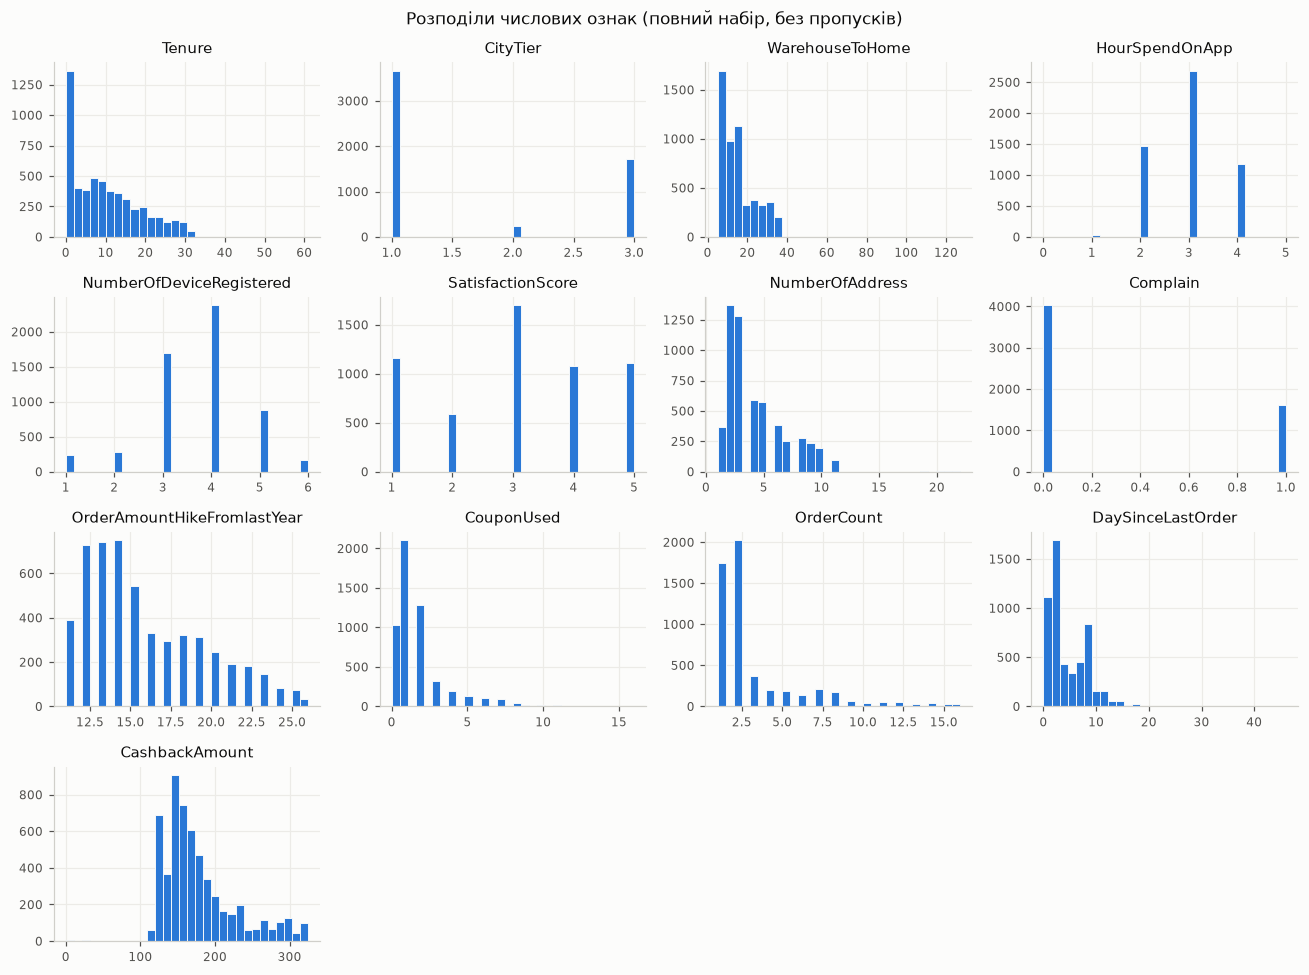

In [7]:
cols = list(num_cols)
fig, axes = plt.subplots(4, 4, figsize=(12, 9))
for ax, col in zip(axes.flat, cols):
    ax.hist(df[col].dropna(), bins=30, color=ACCENT, edgecolor=SURFACE, linewidth=0.6)
    ax.set_title(col)
for ax in axes.flat[len(cols):]:
    ax.set_visible(False)
fig.suptitle("Розподіли числових ознак (повний набір, без пропусків)", color=INK, fontsize=11)
fig.tight_layout()
fig.savefig(REPORTS / "eda_numeric_distributions.png", bbox_inches="tight")
plt.show()

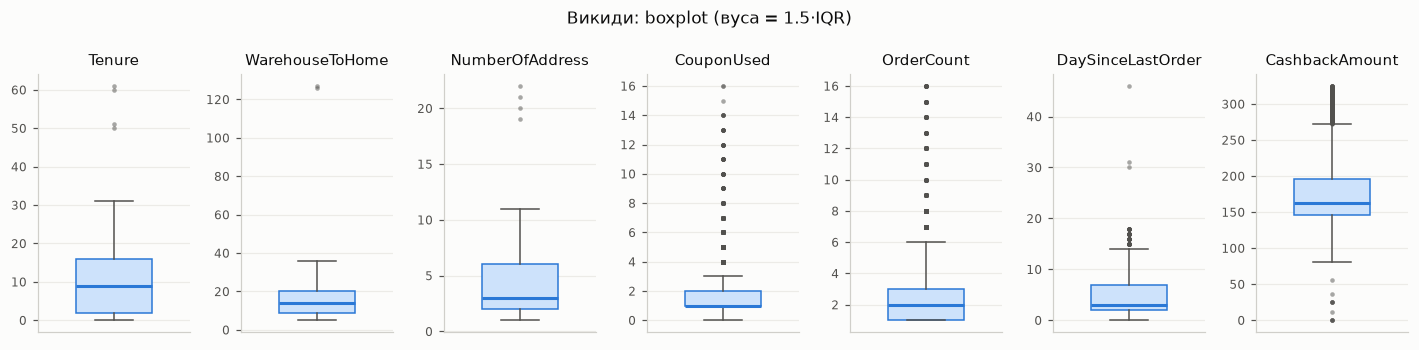

,outlier_share_IQR
Tenure,0.001
WarehouseToHome,0.000
NumberOfAddress,0.001
CouponUsed,0.112
OrderCount,0.125
DaySinceLastOrder,0.011
CashbackAmount,0.078


In [8]:
cont = ["Tenure", "WarehouseToHome", "NumberOfAddress", "CouponUsed", "OrderCount", "DaySinceLastOrder", "CashbackAmount"]
fig, axes = plt.subplots(1, len(cont), figsize=(13, 3.2))
for ax, col in zip(axes, cont):
    ax.boxplot(df[col].dropna(), widths=0.5, patch_artist=True,
               boxprops=dict(facecolor="#cde2fb", edgecolor=ACCENT), medianprops=dict(color=ACCENT, linewidth=2),
               whiskerprops=dict(color=MUTED), capprops=dict(color=MUTED),
               flierprops=dict(marker="o", markersize=3, markerfacecolor=MUTED, markeredgecolor="none", alpha=0.5))
    ax.set_title(col)
    ax.set_xticks([])
fig.suptitle("Викиди: boxplot (вуса = 1.5·IQR)", color=INK, fontsize=11)
fig.tight_layout()
fig.savefig(REPORTS / "eda_outliers_boxplot.png", bbox_inches="tight")
plt.show()

iqr_out = {}
for col in cont:
    q1, q3 = df[col].quantile([0.25, 0.75])
    iqr_out[col] = ((df[col] < q1 - 1.5 * (q3 - q1)) | (df[col] > q3 + 1.5 * (q3 - q1))).mean()
pd.Series(iqr_out, name="outlier_share_IQR").round(3).to_frame()

**Висновки:** більшість кількісних ознак мають правосторонню асиметрію (Tenure, WarehouseToHome, CouponUsed, OrderCount, DaySinceLastOrder) і викиди.
Звідси політика: для адитивних моделей — `log1p → standard_scaler` (усі значення ≥ 0, тому `log1p` визначений),
для розбиваючих — вінсоризація 1%/99% (захист від вузлів, що відокремлюють одиничні викиди).


## 5. Категоріальні ознаки: неузгоджені значення

In [9]:
cat_cols = df.select_dtypes(exclude="number").columns
for col in cat_cols:
    print(f"{col}: {df[col].value_counts().to_dict()}")

PreferredLoginDevice: {'Mobile Phone': 2765, 'Computer': 1634, 'Phone': 1231}
PreferredPaymentMode: {'Debit Card': 2314, 'Credit Card': 1501, 'E wallet': 614, 'UPI': 414, 'COD': 365, 'CC': 273, 'Cash on Delivery': 149}
Gender: {'Male': 3384, 'Female': 2246}
PreferedOrderCat: {'Laptop & Accessory': 2050, 'Mobile Phone': 1271, 'Fashion': 826, 'Mobile': 809, 'Grocery': 410, 'Others': 264}
MaritalStatus: {'Married': 2986, 'Single': 1796, 'Divorced': 848}


Знайдено синоніми: `Phone` ≡ `Mobile Phone` (пристрій), `CC` ≡ `Credit Card`, `COD` ≡ `Cash on Delivery` (оплата), `Mobile` ≡ `Mobile Phone` (категорія).
Вони зводяться безстановим кроком `ValueAliasMapper` (секція `value_aliases` конфігурації) **всередині** конвеєра — щоб те саме відбувалося й у продакшені.


## 6. Дублікати

In [10]:
no_id = df.drop(columns=[dc["id_column"]])
dup = no_id.duplicated(keep=False)
print(f"Рядків, що повністю повторюють інший (без CustomerID): {no_id.duplicated().sum()}")
print(f"Задіяно в групах дублікатів: {dup.sum()} ({dup.mean():.1%})")

Рядків, що повністю повторюють інший (без CustomerID): 556
Задіяно в групах дублікатів: 1112 (19.8%)


⚠️ ~10% рядків — точні копії інших (з різними `CustomerID`). Для ЛР1 це не критично (конвеєр не навчає модель),
але при розбитті на train/test у наступних роботах копія може опинитися по обидва боки — це ще одне джерело завищеної оцінки.
Фіксуємо як ризик якості даних.


## 7. Кандидати на захищену ознаку

In [11]:
view = df.copy()
for col, aliases in {"PreferredLoginDevice": {"Phone": "Mobile Phone"},
                     "PreferredPaymentMode": {"CC": "Credit Card", "COD": "Cash on Delivery"},
                     "PreferedOrderCat": {"Mobile": "Mobile Phone"}}.items():
    view[col] = view[col].replace(aliases)       # лише для аналізу; у конвеєрі це робить ValueAliasMapper

candidates = ["CityTier", "Gender", "PreferredLoginDevice"]
tables = {c: view.groupby(c)[dc["target"]].agg(churn_rate="mean", n="size").round(3) for c in candidates}
pd.concat(tables, names=["attribute", "group"])

churn_rate     n
attribute            group                         
CityTier             1                  0.145  3666
                     2                  0.198   242
                     3                  0.214  1722
Gender               Female             0.155  2246
                     Male               0.177  3384
PreferredLoginDevice Computer           0.198  1634
                     Mobile Phone       0.156  3996

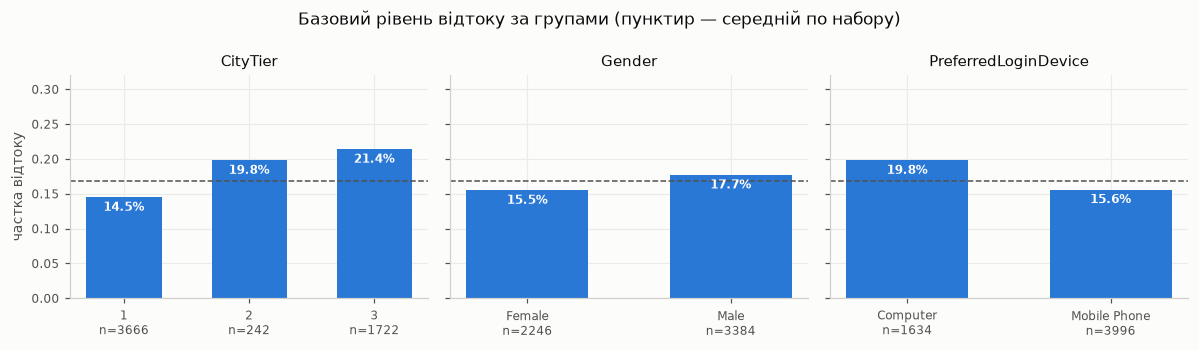

In [12]:
fig, axes = plt.subplots(1, 3, figsize=(11, 3.2), sharey=True)
for ax, col in zip(axes, candidates):
    t = tables[col]
    labels = [f"{i}\nn={n}" for i, n in zip(t.index, t["n"])]
    bars = ax.bar(labels, t["churn_rate"], color=ACCENT, width=0.6)
    for b, v in zip(bars, t["churn_rate"]):
        ax.text(b.get_x() + b.get_width() / 2, v - 0.006, f"{v:.1%}", ha="center", va="top",
                fontsize=8, color="white", fontweight="bold")
    ax.axhline(view[dc["target"]].mean(), color=MUTED, linewidth=1, linestyle="--")
    ax.set_title(col)
axes[0].set_ylabel("частка відтоку")
axes[0].set_ylim(0, 0.32)
fig.suptitle("Базовий рівень відтоку за групами (пунктир — середній по набору)", color=INK, fontsize=11)
fig.tight_layout()
fig.savefig(REPORTS / "eda_churn_by_group.png", bbox_inches="tight")
plt.show()

**Рішення:** `protected_attributes: [CityTier, Gender]`
*(за ТЗ основна обирається між географією і типом пристрою — обрано `CityTier`; додатково до захищених віднесено й стать)*.

- **`CityTier`** — основна: за нею рахуватимуться метрики справедливості. Базові рівні відтоку різні:
  Tier 1 — 14.5%, Tier 2 — 19.8%, Tier 3 — 21.4%; це важливо для вибору між DPR та EOR.
- **`Gender`** — архітектурно виключена: стать — захищена характеристика, а її прогностична цінність мала (15.5% vs 17.7%).
- Тип пристрою відхилено як захищену ознаку: це поведінкова звичка, а не характеристика людини (ТЗ описує його як проксі платоспроможності).


## 8. Проксі-ознаки для CityTier

In [13]:
from scipy.stats.contingency import association
from scipy.stats import kruskal

rows = []
for col in list(cat_cols) + ["SatisfactionScore", "Complain"]:
    v = association(pd.crosstab(view[col], view["CityTier"]).values, method="cramer")
    rows.append({"feature": col, "type": "categorical", "cramers_v": round(v, 3)})
proxy_cat = pd.DataFrame(rows).sort_values("cramers_v", ascending=False)

rows = []
for col in num_cols.drop(["CityTier", "SatisfactionScore", "Complain"]):
    groups = [g.dropna() for _, g in view.groupby("CityTier")[col]]
    h, p = kruskal(*groups)
    n = sum(len(g) for g in groups)
    eps2 = (h - len(groups) + 1) / (n - len(groups))   # розмір ефекту ε² для Kruskal–Wallis
    rows.append({"feature": col, "type": "numeric", "epsilon_sq": round(eps2, 4), "p_value": p})
proxy_num = pd.DataFrame(rows).sort_values("epsilon_sq", ascending=False)
display(proxy_cat, proxy_num)

,feature,type,cramers_v
1,PreferredPaymentMode,categorical,0.437
3,PreferedOrderCat,categorical,0.218
5,SatisfactionScore,categorical,0.063
2,Gender,categorical,0.049
4,MaritalStatus,categorical,0.046
6,Complain,categorical,0.014
0,PreferredLoginDevice,categorical,0.012


,feature,type,epsilon_sq,p_value
9,CashbackAmount,numeric,0.0185,8.168984e-24
0,Tenure,numeric,0.0043,3.407640e-06
5,OrderAmountHikeFromlastYear,numeric,0.0018,3.253846e-03
7,OrderCount,numeric,0.0008,4.053729e-02
4,NumberOfAddress,numeric,0.0005,8.925399e-02
1,WarehouseToHome,numeric,0.0003,1.659226e-01
6,CouponUsed,numeric,0.0002,2.393077e-01
3,NumberOfDeviceRegistered,numeric,0.0001,2.932248e-01
2,HourSpendOnApp,numeric,-0.0000,3.902455e-01
8,DaySinceLastOrder,numeric,0.0000,3.443241e-01


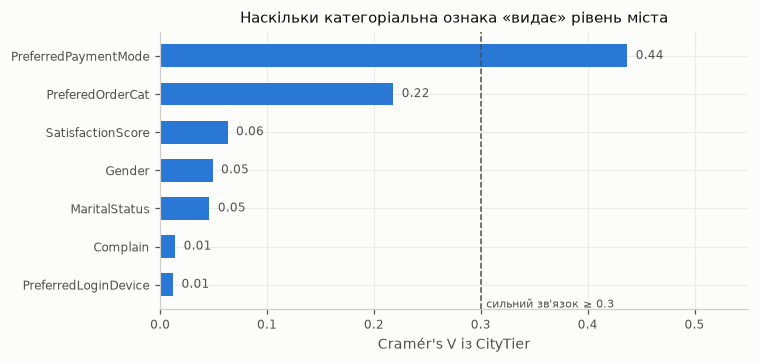

CityTier,1,2,3
PreferredPaymentMode,,,
Cash on Delivery,366,16,132
Credit Card,1382,50,342
Debit Card,1676,62,576
E wallet,0,0,614
UPI,242,114,58


In [14]:
fig, ax = plt.subplots(figsize=(7, 3.4))
pc = proxy_cat.sort_values("cramers_v")
ax.barh(pc["feature"], pc["cramers_v"], color=ACCENT, height=0.6)
for yy, v in enumerate(pc["cramers_v"]):
    ax.text(v + 0.008, yy, f"{v:.2f}", va="center", fontsize=8, color=MUTED)
ax.axvline(0.3, color=MUTED, linestyle="--", linewidth=1)
ax.text(0.305, -0.6, "сильний зв'язок ≥ 0.3", fontsize=7.5, color=MUTED)
ax.set_xlabel("Cramér's V із CityTier")
ax.set_xlim(0, 0.55)
ax.set_title("Наскільки категоріальна ознака «видає» рівень міста")
fig.tight_layout()
fig.savefig(REPORTS / "eda_proxy_cramers_v.png", bbox_inches="tight")
plt.show()
pd.crosstab(view["PreferredPaymentMode"], view["CityTier"])

**Висновки щодо проксі:**
- **`PreferredPaymentMode` — сильний проксі** (V ≈ 0.44): `E wallet` трапляється **лише** в Tier 3, `UPI` непропорційно частий у Tier 2.
  Модель може відновити частину інформації про рівень міста саме через цю ознаку.
- `PreferedOrderCat` — помірний зв'язок (V ≈ 0.2); `MaritalStatus`, `SatisfactionScore` (≈ 0.05) — слабкі.
- `Gender` — V ≈ 0.05, тобто не є проксі рівня міста (до моделі не входить як друга захищена ознака).
- `PreferredLoginDevice` — V ≈ 0.01 **після** зведення синонімів (на сирих даних ≈ 0.11): «зв'язок» з рівнем міста
  створювала сама неузгодженість міток `Phone`/`Mobile Phone`, а не реальна поведінка клієнтів.
- Числові ознаки практично не залежать від CityTier (ε² ≈ 0).

`PreferredPaymentMode` **залишено** у `features` (спосіб оплати має пряму бізнес-цінність для прогнозу відтоку), але позначено як ризик:
коли з'явиться модель, метрики справедливості за CityTier слід перевірити з і без `PreferredPaymentMode`.
Виключення `CityTier` саме по собі **не гарантує** відсутності дискримінації.
